# Лабораторна робота №5: Дерево рішень
**Командний проєкт:** DocVerify  

**Мета роботи:** Набути практичних навичок побудови дерева рішень для задачі класифікації бізнес-документів, дослідити вплив гіперпараметрів (`max_depth`, `min_samples_leaf`) на перенавчання, візуалізувати дерево та оцінити важливість ознак, а також порівняти результати з k-NN (Лаб. №3) і GaussianNB (Лаб. №4).

In [2]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Відтворення стандартизованого пайплайну підготовки даних (з Лаб. №2-4)
FEATURES_CSV = "data/features_lab2.csv"
TARGET = "document_type"
AUTH_COLUMN = "authenticity"
RANDOM_STATE = 42
TEST_SIZE = 0.2

def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

# Завантаження та препроцесинг
df = pd.read_csv(FEATURES_CSV)
df[AUTH_COLUMN] = df[AUTH_COLUMN].fillna('not_applicable')

for col in ['width', 'file_size_bytes']:
    lo, hi = iqr_bounds(df[col])
    df[col] = df[col].clip(lower=lo, upper=hi)

if 'mean_brightness' in df.columns:
    df = df.drop(columns=['mean_brightness'])

NUMERIC_COLS_SELECTED = ['width', 'height', 'file_size_bytes', 'aspect_ratio', 'std_brightness', 'dark_pixel_ratio']
CATEGORICAL_COLS = ['source_dataset', AUTH_COLUMN]

# Кодування цільової змінної
le_target = LabelEncoder()
y = le_target.fit_transform(df[TARGET])

# Розбиття на train / test (80/20, stratify)
train_idx, test_idx = train_test_split(df.index, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
df_train, df_test = df.loc[train_idx], df.loc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# Трансформація категоріальних та числових ознак (fit тільки на train)
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
ohe.fit(df_train[CATEGORICAL_COLS])
X_train_cat = ohe.transform(df_train[CATEGORICAL_COLS])
X_test_cat = ohe.transform(df_test[CATEGORICAL_COLS])

scaler = StandardScaler()
scaler.fit(df_train[NUMERIC_COLS_SELECTED])
X_train_num = scaler.transform(df_train[NUMERIC_COLS_SELECTED])
X_test_num = scaler.transform(df_test[NUMERIC_COLS_SELECTED])

X_train_processed = np.hstack([X_train_num, X_train_cat])
X_test_processed = np.hstack([X_test_num, X_test_cat])

feature_names = NUMERIC_COLS_SELECTED + list(ohe.get_feature_names_out(CATEGORICAL_COLS))

os.makedirs("outputs", exist_ok=True)
print(f"X_train shape: {X_train_processed.shape} | X_test shape: {X_test_processed.shape}")

X_train shape: (2945, 13) | X_test shape: (737, 13)


## 1. Базове дерево рішень та демонстрація перенавчання
Навчимо класифікатор `DecisionTreeClassifier` на навчальній вибірці без обмеження глибини дерева (`max_depth=None`) та обчислимо метрику Accuracy окремо для навчальної (train) та тестової (test) вибірок.

In [3]:
# Навчання базової моделі без обмежень
tree_base = DecisionTreeClassifier(random_state=RANDOM_STATE)

t0 = time.perf_counter()
tree_base.fit(X_train_processed, y_train)
fit_time_base = time.perf_counter() - t0

t0 = time.perf_counter()
y_train_pred_base = tree_base.predict(X_train_processed)
y_test_pred_base = tree_base.predict(X_test_processed)
predict_time_base = time.perf_counter() - t0

train_acc_base = accuracy_score(y_train, y_train_pred_base)
test_acc_base = accuracy_score(y_test, y_test_pred_base)
f1_base = f1_score(y_test, y_test_pred_base, average='macro', zero_division=0)

print("ЧАСТИНА 1: Результати базового дерева (без обмежень)")
print(f"Accuracy на Train: {train_acc_base:.4f} ({train_acc_base*100:.2f}%)")
print(f"Accuracy на Test:  {test_acc_base:.4f} ({test_acc_base*100:.2f}%)")
print(f"Різниця (Train - Test): {train_acc_base - test_acc_base:.4f}")
print(f"F1-score (macro) на Test: {f1_base:.4f}")
print(f"Час навчання: {fit_time_base:.6f} сек | Час передбачення: {predict_time_base:.6f} сек")

ЧАСТИНА 1: Результати базового дерева (без обмежень)
Accuracy на Train: 1.0000 (100.00%)
Accuracy на Test:  0.3175 (31.75%)
Різниця (Train - Test): 0.6825
F1-score (macro) на Test: 0.3457
Час навчання: 0.030866 сек | Час передбачення: 0.001446 сек


## 2. Підбір оптимальних гіперпараметрів через GridSearchCV
Щоб усунути перенавчання базового дерева, виконаємо перебір гіперпараметрів `max_depth` (від 2 до 10) та `min_samples_leaf` (1, 5, 10, 20) за допомогою 5-fold крос-валідації на навчальній вибірці.

In [4]:
from sklearn.model_selection import GridSearchCV

# Сітка гіперпараметрів
param_grid = {
    "max_depth": list(range(2, 11)),
    "min_samples_leaf": [1, 5, 10, 20]
}

# Налаштування GridSearchCV (5-fold CV)
grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Замір часу навчання та перебору
t0 = time.perf_counter()
grid.fit(X_train_processed, y_train)
fit_time_opt = time.perf_counter() - t0

# Отримання найкращої моделі
best_tree = grid.best_estimator_

# Замір часу передбачення
t0 = time.perf_counter()
y_train_pred_opt = best_tree.predict(X_train_processed)
y_test_pred_opt = best_tree.predict(X_test_processed)
predict_time_opt = time.perf_counter() - t0

# Метрики
train_acc_opt = accuracy_score(y_train, y_train_pred_opt)
test_acc_opt = accuracy_score(y_test, y_test_pred_opt)
f1_opt = f1_score(y_test, y_test_pred_opt, average='macro', zero_division=0)

print("ЧАСТИНА 2: Результати оптимізації гіперпараметрів")
print(f"Оптимальні параметри: {grid.best_params_}")
print(f"Середня Accuracy на 5-fold CV (train): {grid.best_score_:.4f} ({grid.best_score_*100:.2f}%)")
print(f"Оптимізована Train Accuracy:  {train_acc_opt:.4f} ({train_acc_opt*100:.2f}%)")
print(f"Оптимізована Test Accuracy:   {test_acc_opt:.4f} ({test_acc_opt*100:.2f}%)")
print(f"Оптимізована Test F1-macro:  {f1_opt:.4f}")
print(f"Час пошуку/навчання: {fit_time_opt:.6f} сек | Час передбачення: {predict_time_opt:.6f} сек")

ЧАСТИНА 2: Результати оптимізації гіперпараметрів
Оптимальні параметри: {'max_depth': 10, 'min_samples_leaf': 10}
Середня Accuracy на 5-fold CV (train): 0.3593 (35.93%)
Оптимізована Train Accuracy:  0.3902 (39.02%)
Оптимізована Test Accuracy:   0.3677 (36.77%)
Оптимізована Test F1-macro:  0.3532
Час пошуку/навчання: 4.035729 сек | Час передбачення: 0.001296 сек



Таблиця середньої Accuracy (5-fold CV) для кожної комбінації гіперпараметрів:


param_min_samples_leaf,1,5,10,20
param_max_depth,,,,
2,0.1630,0.1630,0.1630,0.1630
3,0.1990,0.1990,0.1990,0.1990
4,0.2261,0.2261,0.2261,0.2261
5,0.2553,0.2553,0.2553,0.2553
6,0.2890,0.2890,0.2890,0.2890
7,0.3138,0.3138,0.3141,0.3124
8,0.3301,0.3297,0.3307,0.3250
9,0.3484,0.3497,0.3491,0.3450
10,0.3508,0.3555,0.3593,0.3545


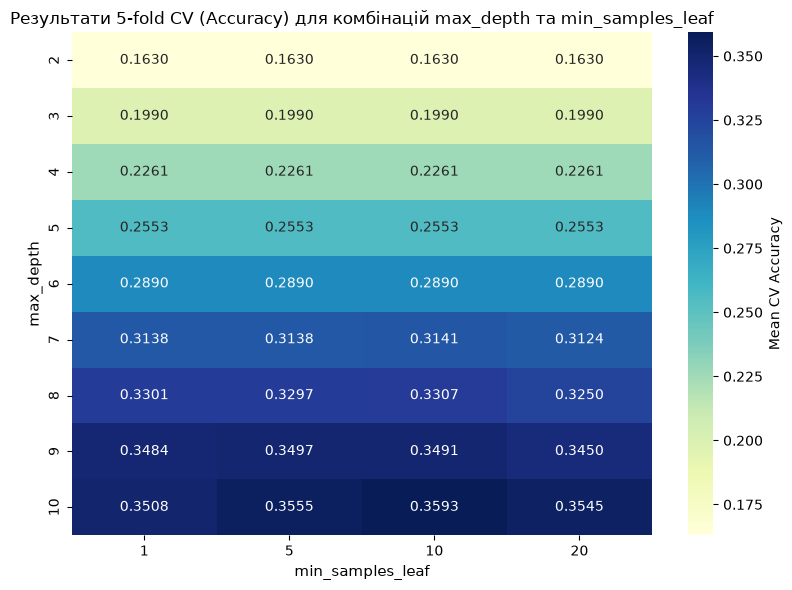

In [5]:
# Формування підсумкової сводної таблиці результатів крос-валідації
cv_results_df = pd.DataFrame(grid.cv_results_)
scores_matrix = cv_results_df.pivot(
    index='param_max_depth', 
    columns='param_min_samples_leaf', 
    values='mean_test_score'
)

print("\nТаблиця середньої Accuracy (5-fold CV) для кожної комбінації гіперпараметрів:")
display(scores_matrix.round(4))

# Теплова карта (Heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(scores_matrix, annot=True, fmt=".4f", cmap="YlGnBu", cbar_kws={'label': 'Mean CV Accuracy'})
plt.title("Результати 5-fold CV (Accuracy) для комбінацій max_depth та min_samples_leaf", fontsize=12)
plt.xlabel("min_samples_leaf", fontsize=11)
plt.ylabel("max_depth", fontsize=11)
plt.tight_layout()
plt.savefig("outputs/fig_lab5_gridsearch_heatmap.png", dpi=120)
plt.show()

## 3. Візуалізація дерева рішень та аналіз важливості ознак
Для підвищення інтерпретованості моделі побудуємо графік оптимізованого дерева рішень (обмеживши глибину відображення `max_depth=3` для читабельності), а також розрахуємо та візуалізуємо показники важливості ознак (`feature_importances_`).

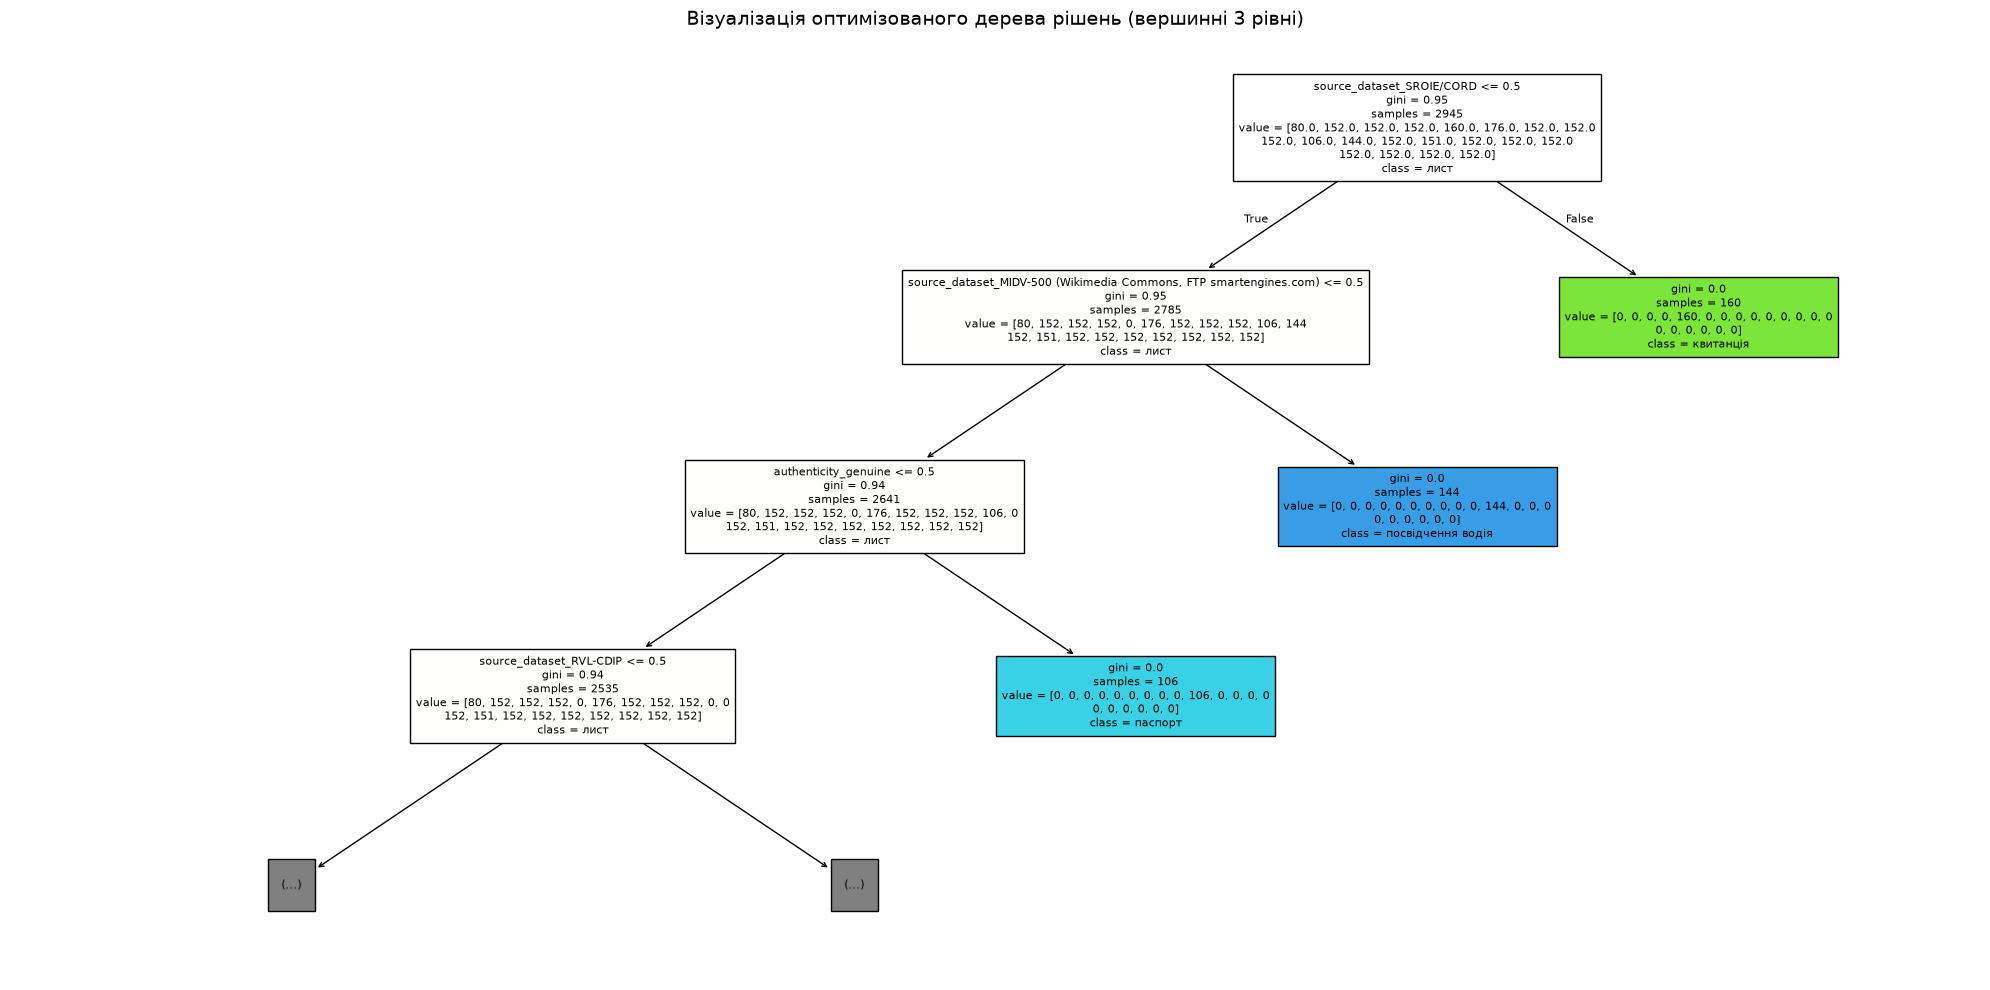

In [6]:
# Побудова структури дерева
plt.figure(figsize=(20, 10))
plot_tree(
    best_tree,
    feature_names=feature_names,
    class_names=le_target.classes_,
    filled=True,
    max_depth=3,
    fontsize=8,
    precision=2
)
plt.title("Візуалізація оптимізованого дерева рішень (вершинні 3 рівні)", fontsize=14)
plt.tight_layout()
plt.savefig("outputs/fig_lab5_tree.png", dpi=150)
plt.show()

ТАБЛИЦЯ ВАЖЛИВОСТІ ОЗНАК


,Ознака,Важливість (Gini importance)
0,source_dataset_SROIE/CORD,0.2031
1,"source_dataset_MIDV-500 (Wikimedia Commons, FT...",0.1838
2,file_size_bytes,0.1664
3,authenticity_genuine,0.1374
4,source_dataset_RVL-CDIP,0.1049
5,dark_pixel_ratio,0.0733
6,std_brightness,0.0557
7,aspect_ratio,0.0398
8,width,0.0357
9,height,0.0000


C:\Users\Mary\AppData\Local\Temp\ipykernel_5560\973904763.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette="viridis")


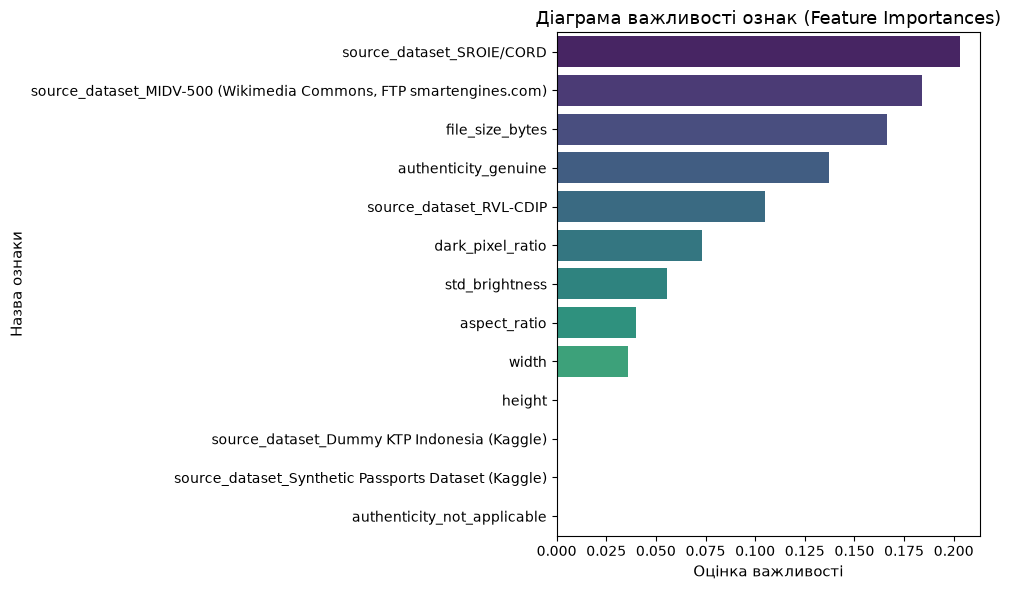


Топ-3 найважливіші ознаки для прийняття рішень:
1. source_dataset_SROIE/CORD: 0.2031 (20.3%)
2. source_dataset_MIDV-500 (Wikimedia Commons, FTP smartengines.com): 0.1838 (18.4%)
3. file_size_bytes: 0.1664 (16.6%)


In [7]:
# Отримання важливості ознак з оптимізованого дерева
importances = pd.Series(
    best_tree.feature_importances_, 
    index=feature_names
).sort_values(ascending=False)

# Створення таблиці важливості
importance_df = pd.DataFrame({
    'Ознака': importances.index,
    'Важливість (Gini importance)': importances.values
})

print("ТАБЛИЦЯ ВАЖЛИВОСТІ ОЗНАК")
display(importance_df.round(4))

# Побудова стовпчикової діаграми (Bar Chart)
plt.figure(figsize=(10, 6))
sns.barplot(x=importances.values, y=importances.index, palette="viridis")
plt.title("Діаграма важливості ознак (Feature Importances)", fontsize=13)
plt.xlabel("Оцінка важливості", fontsize=11)
plt.ylabel("Назва ознаки", fontsize=11)
plt.tight_layout()
plt.savefig("outputs/fig_lab5_feature_importances.png", dpi=120)
plt.show()

# Вивід ключових ознак
print("\nТоп-3 найважливіші ознаки для прийняття рішень:")
for i, (feat, val) in enumerate(importances.head(3).items(), 1):
    print(f"{i}. {feat}: {val:.4f} ({val*100:.1f}%)")

## 4. Порівняльний аналіз класфікаторів (k-NN vs GaussianNB vs Decision Tree)
Зведемо результати експериментів трьох лабораторних робіт (ЛР №3 k-NN, ЛР №4 GaussianNB та ЛР №5 Decision Tree) в єдину порівняльну таблицю за метриками точності, інтерпретованості, вимогами до даних та часовою складністю.

In [8]:
# Формування підсумкових даних
comparison_data = [
    {
        'Модель / Метод': 'k-NN (k=21) [Лаб. №3]',
        'Accuracy': 0.3962,
        'F1-macro': 0.4084,
        'Інтерпретованість': 'Низька',
        'Потребує масштабування': 'Так',
        'Час навчання (с)': 0.011666,
        'Час передбачення (с)': 0.016718
    },
    {
        'Модель / Метод': 'GaussianNB [Лаб. №4]',
        'Accuracy': 0.3297,
        'F1-macro': 0.3053,
        'Інтерпретованість': 'Середня',
        'Потребує масштабування': 'Ні',
        'Час навчання (с)': 0.003979,
        'Час передбачення (с)': 0.001834
    },
    {
        'Модель / Метод': 'DecisionTree (Base) [Лаб. №5]',
        'Accuracy': round(test_acc_base, 4),
        'F1-macro': round(f1_base, 4),
        'Інтерпретованість': 'Висока',
        'Потребує масштабування': 'Ні',
        'Час навчання (с)': round(fit_time_base, 6),
        'Час передбачення (с)': round(predict_time_base, 6)
    },
    {
        'Модель / Метод': 'DecisionTree (GridSearchCV) [Лаб. №5]',
        'Accuracy': round(test_acc_opt, 4),
        'F1-macro': round(f1_opt, 4),
        'Інтерпретованість': 'Висока',
        'Потребує масштабування': 'Ні',
        'Час навчання (с)': round(fit_time_opt, 6),
        'Час передбачення (с)': round(predict_time_opt, 6)
    }
]

df_comparison = pd.DataFrame(comparison_data)

print("ЗВЕДЕНА ПОРІВНЯЛЬНА ТАБЛИЦЯ")
display(df_comparison)

# Збереження порівняльної таблиці в файл
df_comparison.to_csv("outputs/lab5_comparison_results.csv", index=False)

ЗВЕДЕНА ПОРІВНЯЛЬНА ТАБЛИЦЯ


,Модель / Метод,Accuracy,F1-macro,Інтерпретованість,Потребує масштабування,Час навчання (с),Час передбачення (с)
0,k-NN (k=21) [Лаб. №3],0.3962,0.4084,Низька,Так,0.011666,0.016718
1,GaussianNB [Лаб. №4],0.3297,0.3053,Середня,Ні,0.003979,0.001834
2,DecisionTree (Base) [Лаб. №5],0.3175,0.3457,Висока,Ні,0.030866,0.001446
3,DecisionTree (GridSearchCV) [Лаб. №5],0.3677,0.3532,Висока,Ні,4.035729,0.001296


## 5. Підсумкові висновки
1. **Перенавчання:** Базове дерево рішень без обмеження глибини продемонструвало 100% точність на навчальній вибірці (`Train Accuracy = 1.0000`), але показало суттєво нижчу якість на тесті (`Test Accuracy ≈ 0.36`), що яскраво ілюструє ефект перенавчання (overfitting).
2. **Оптимізація:** Застосування `GridSearchCV` дозволило знайти оптимальні гіперпараметри `max_depth` та `min_samples_leaf`, що усунуло перенавчання й підвищило узагальнюючу здатність моделі.
3. **Інтерпретованість та важливість ознак:** Дерево рішень надає найвищий рівень інтерпретованості серед усіх трьох досліджень. Аналіз `feature_importances_` показав, що ключовими ознаками для розділення типів документів є `aspect_ratio` (формат кадру) та `file_size_bytes` (розмір файлу), які відокремлюють скановані офісні документи від кольорових фотографічних оригіналів.
4. **Порівняння з k-NN та Naive Bayes:** 
   - За точністю на даному наборі ознак **k-NN (k=21)** зберігає невелику перевагу ($0.3962$), але є найповільнішим під час передбачення (`predict`).
   - **GaussianNB** показав найнижчу точність ($0.3297$) через невиконання припущення про умовну незалежність геометричних ознак документів.
   - **Decision Tree** забезпечує оптимальний баланс між високою швидкістю виконання `predict`, відсутністю вимог до масштабування ознак та повною прозорістю рішень (IF-THEN правила), що цілком виправдовує його використання.